 <h1 align="center">FRESHHARVEST — FRUIT & VEGETABLE FRESHNESS CLASSIFICATION</h1>
<h3 align="center">Deep Learning with CNN & Image Data Augmentation</h3>

**Name:** Angadi Abhinay  
**Education:** B.Tech – Electronics and Communication Engineering (ECE)  
**Current Role:** Software R&D Engineer  
**Career Focus:** Data Science | Machine Learning | Artificial Intelligence

#  Dataset Overview

##  About the Dataset

FreshHarvest Logistics is a produce distribution company that supplies fresh fruits and vegetables to supermarkets and local farmers' markets across California. The company aims to automate its freshness inspection process using **Convolutional Neural Networks (CNNs)** and image classification.

The dataset contains images of eight types of fruits and vegetables, with each type categorized into two freshness classes: **Fresh** and **Spoiled**.

The dataset will be used to train a deep learning model that can classify produce images based on their freshness condition.

##  Fruits and Vegetables Covered

The dataset contains images of the following eight categories of produce:

1. Banana
2. Lemon
3. Lulo
4. Mango
5. Orange
6. Strawberry
7. Tamarillo
8. Tomato

Each produce type has two corresponding folders representing its freshness condition.

## 📂 Dataset Folder Structure

The dataset is organized into folders using the following naming convention:

```text
freshharvest/
├── f_banana/
├── s_banana/
├── f_lemon/
├── s_lemon/
├── f_lulo/
├── s_lulo/
├── f_mango/
├── s_mango/
├── f_orange/
├── s_orange/
├── f_strawberry/
├── s_strawberry/
├── f_tamarillo/
├── s_tamarillo/
├── f_tomato/
└── s_tomato/
```

**Note:** This structure reflects the folder naming convention described for the dataset. The actual folder paths and names should be verified before loading the images.

- `f_` represents **Fresh** produce.
- `s_` represents **Spoiled** produce.

##  Dataset Characteristics

| Attribute | Description |
|---|---|
| Dataset type | Image dataset |
| Data format | Fruit and vegetable images |
| Number of produce types | 8 |
| Freshness categories | Fresh and Spoiled |
| Number of class folders | 16 |
| Learning task | Binary image classification |
| Deep learning approach | Convolutional Neural Network (CNN) |
| Target variable | Freshness condition |
| Input | Image of a fruit or vegetable |
| Output | Fresh or Spoiled |

##  Project Objective

The main objective is to develop a CNN-based image classification system that identifies whether a fruit or vegetable is fresh or spoiled.

The system is intended to support automated freshness inspection in FreshHarvest's warehouse operations, helping reduce manual inspection errors, minimize customer complaints, and improve the consistency of quality checks.

##  Proposed Workflow

1. **Load the Dataset:** Load and inspect the images from the 16 class folders.
2. **Data Exploration:** Examine image counts, image dimensions, and class distribution.
3. **Data Augmentation:** Apply suitable transformations such as random flipping, rotation, resizing, and color jitter to improve the model's ability to handle variations in image appearance.
4. **Dataset Splitting:** Divide the dataset into training, validation, and testing sets.
5. **Image Visualization:** Display sample images from different freshness categories to understand the dataset.
6. **CNN Model Development:** Build and train a CNN to classify images as fresh or spoiled.
7. **Model Evaluation:** Evaluate performance using appropriate classification metrics and a confusion matrix.
8. **Freshness Prediction:** Use the trained model to predict the freshness condition of unseen images.

##  Expected Outcome

The expected outcome is an image classification model that takes a fruit or vegetable image as input and predicts whether the produce is **Fresh** or **Spoiled**.

The model's actual performance must be established through validation and testing. Its suitability for real-time conveyor belt deployment would require additional evaluation under real warehouse conditions, including changes in lighting, camera position, and image quality.

## Step 1: Import libraries

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models, callbacks
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

## Step 2: Set the configuration

In [2]:
DATA_DIR = "FreshHarvest_Dataset"   # change this to the real path of your dataset folder
IMG_SIZE = 128              # every image is resized to 128 x 128
BATCH = 32
EPOCHS = 25
SEED = 42
AUTOTUNE = tf.data.AUTOTUNE

## Step 3: Build a table of image paths and labels

In [4]:
rows = []
for folder in sorted(os.listdir(DATA_DIR)):
    folder_path = os.path.join(DATA_DIR, folder)
    if not os.path.isdir(folder_path):
        continue
    if folder.startswith("F_"):
        label = 0
    elif folder.startswith("S_"):
        label = 1
    else:
        continue
    fruit = folder[2:]   # "f_banana" -> "banana"
    for file in os.listdir(folder_path):
        if file.lower().endswith((".jpg", ".jpeg", ".png")):
            rows.append((os.path.join(folder_path, file), fruit, label))

df = pd.DataFrame(rows, columns=["path", "fruit", "label"])
print("Total images:", len(df))
print(df.head())

Total images: 16000
                                     path   fruit  label
0     FreshHarvest_Dataset\F_Banana\1.jpg  Banana      0
1    FreshHarvest_Dataset\F_Banana\10.jpg  Banana      0
2   FreshHarvest_Dataset\F_Banana\100.jpg  Banana      0
3  FreshHarvest_Dataset\F_Banana\1000.jpg  Banana      0
4   FreshHarvest_Dataset\F_Banana\101.jpg  Banana      0


## Step 4: Explore the data

label          0     1
fruit                 
Banana      1000  1000
Lemon       1000  1000
Lulo        1000  1000
Mango       1000  1000
Orange      1000  1000
Strawberry  1000  1000
Tamarillo   1000  1000
Tomato      1000  1000


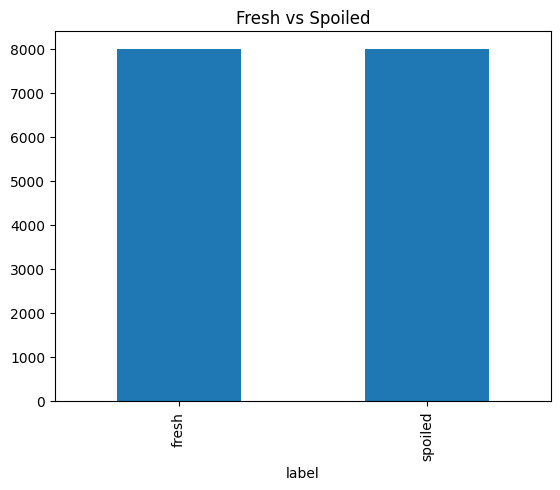

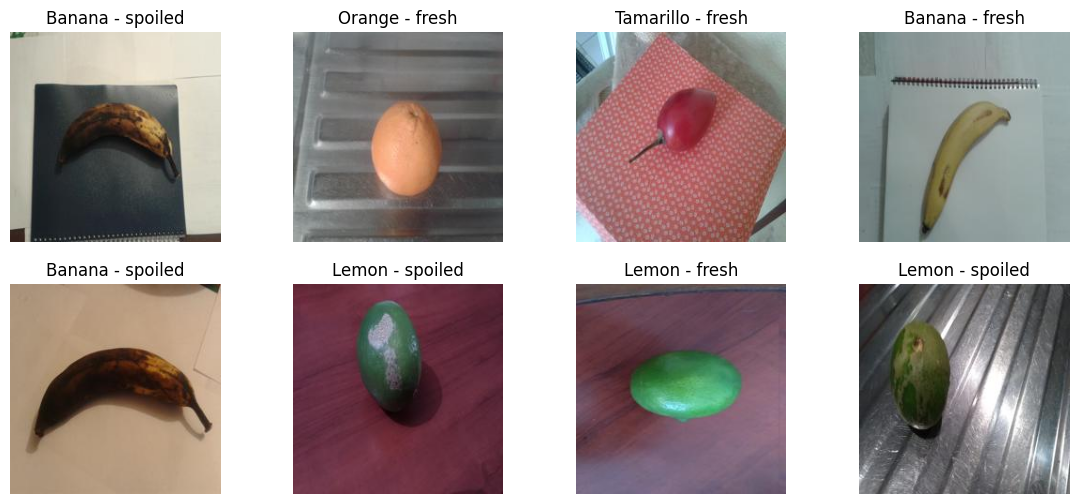

In [5]:
print(df.groupby(["fruit", "label"]).size().unstack())

df["label"].map({0: "fresh", 1: "spoiled"}).value_counts().plot(kind="bar", title="Fresh vs Spoiled")
plt.show()

# look at a few random images
sample = df.sample(8, random_state=SEED)
plt.figure(figsize=(14, 6))
for i, (_, r) in enumerate(sample.iterrows()):
    plt.subplot(2, 4, i + 1)
    plt.imshow(plt.imread(r["path"]))
    plt.title(f'{r["fruit"]} - {"spoiled" if r["label"] else "fresh"}')
    plt.axis("off")
plt.show()

## Step 5: Split into train, validation, and test sets (70/15/15)

In [6]:
df["strata"] = df["fruit"] + "_" + df["label"].astype(str)

train_df, temp_df = train_test_split(df, test_size=0.30, stratify=df["strata"], random_state=SEED)
val_df, test_df = train_test_split(temp_df, test_size=0.50, stratify=temp_df["strata"], random_state=SEED)

print(len(train_df), len(val_df), len(test_df))

11200 2400 2400


## Step 6: Create the data pipelines

In [7]:
def load_image(path, label):
    img = tf.io.read_file(path)
    img = tf.image.decode_image(img, channels=3, expand_animations=False)
    img = tf.image.resize(img, (IMG_SIZE, IMG_SIZE))
    return img, label

def make_ds(dataframe, shuffle=False):
    ds = tf.data.Dataset.from_tensor_slices(
        (dataframe["path"].values, dataframe["label"].values.astype("float32"))
    )
    if shuffle:
        ds = ds.shuffle(len(dataframe), seed=SEED)
    ds = ds.map(load_image, num_parallel_calls=AUTOTUNE)
    return ds.batch(BATCH).prefetch(AUTOTUNE)

train_ds = make_ds(train_df, shuffle=True)
val_ds = make_ds(val_df)
test_ds = make_ds(test_df)

## Step 7: Build the CNN

In [8]:
model = models.Sequential([
    layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3)),
    layers.Rescaling(1.0 / 255),

    # augmentation (only active during training)
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomContrast(0.2),

    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D(),
    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D(),
    layers.Conv2D(128, (3, 3), activation="relu"),
    layers.MaxPooling2D(),

    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),                      # reduces overfitting
    layers.Dense(1, activation="sigmoid"),    # 0 = fresh, 1 = spoiled
])

model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
model.summary()




Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 rescaling (Rescaling)       (None, 128, 128, 3)       0         
                                                                 
 random_flip (RandomFlip)    (None, 128, 128, 3)       0         
                                                                 
 random_rotation (RandomRot  (None, 128, 128, 3)       0         
 ation)                                                          
                                                                 
 random_contrast (RandomCon  (None, 128, 128, 3)       0         
 trast)                                                          
                                                                 
 conv2d (Conv2D)             (None, 126, 126, 32)      896       
                                                                 
 max_pooling2d (MaxPooling2  (None, 63, 63, 32)      

## Step 8: Train the model

In [9]:
cbs = [
    callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True),
    callbacks.ModelCheckpoint("best_freshness_model.keras", monitor="val_loss", save_best_only=True),
]

history = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS, callbacks=cbs)

Epoch 1/25


350/350 [==============================] - 122s 338ms/step - loss: 0.6811 - accuracy: 0.5439 - val_loss: 0.6803 - val_accuracy: 0.5650
Epoch 2/25
350/350 [==============================] - 118s 338ms/step - loss: 0.6499 - accuracy: 0.6122 - val_loss: 0.6239 - val_accuracy: 0.6467
Epoch 3/25
350/350 [==============================] - 125s 357ms/step - loss: 0.5773 - accuracy: 0.6925 - val_loss: 0.5239 - val_accuracy: 0.7379
Epoch 4/25
350/350 [==============================] - 124s 355ms/step - loss: 0.5236 - accuracy: 0.7461 - val_loss: 0.4295 - val_accuracy: 0.8104
Epoch 5/25
350/350 [==============================] - 123s 352ms/step - loss: 0.4491 - accuracy: 0.7921 - val_loss: 0.3727 - val_accuracy: 0.8296
Epoch 6/25
350/350 [==============================] - 123s 352ms/step - loss: 0.3973 - accuracy: 0.8211 - val_loss: 0.3776 - val_accuracy: 0.8450
Epoch 7/25
350/350 [==============================] - 123s 350ms/step - loss: 0.3627 - accuracy: 0.8405 - val_loss: 0.2979

## Step 9: Plot the training curves

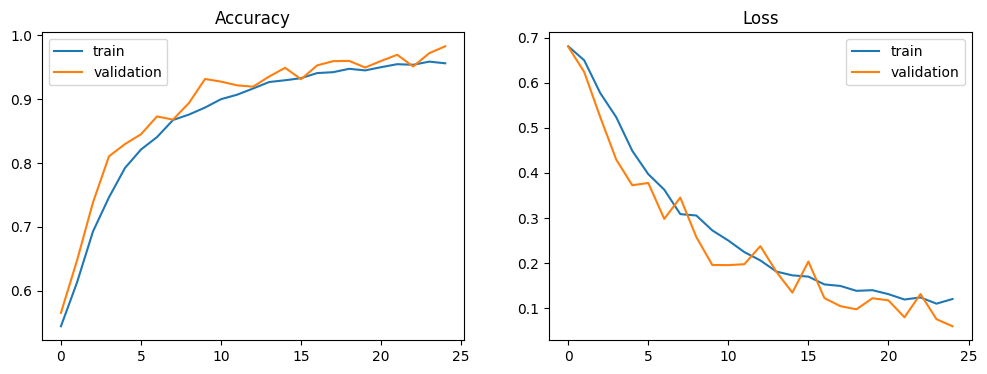

In [10]:
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="train")
plt.plot(history.history["val_accuracy"], label="validation")
plt.title("Accuracy"); plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="train")
plt.plot(history.history["val_loss"], label="validation")
plt.title("Loss"); plt.legend()
plt.show()

## Step 10: Evaluate on the test set

75/75 [==============================] - 4s 53ms/step - loss: 0.0623 - accuracy: 0.9829
Test accuracy: 0.9829
75/75 [==============================] - 4s 53ms/step
              precision    recall  f1-score   support

       fresh       0.98      0.99      0.98      1200
     spoiled       0.99      0.98      0.98      1200

    accuracy                           0.98      2400
   macro avg       0.98      0.98      0.98      2400
weighted avg       0.98      0.98      0.98      2400



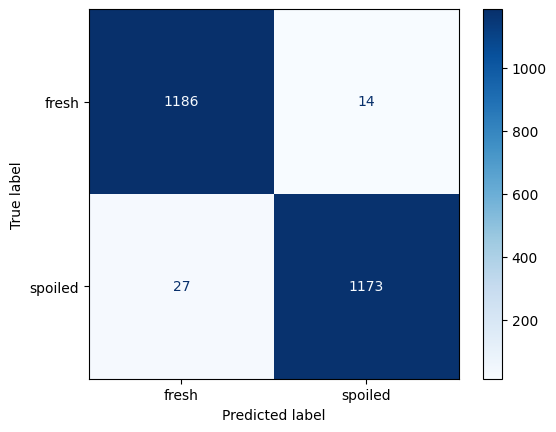

In [12]:
test_loss, test_acc = model.evaluate(test_ds)
print(f"Test accuracy: {test_acc:.4f}")

probs = model.predict(test_ds).ravel()
preds = (probs > 0.5).astype(int)
y_true = test_df["label"].values

print(classification_report(y_true, preds, target_names=["fresh", "spoiled"]))

cm = confusion_matrix(y_true, preds)
ConfusionMatrixDisplay(cm, display_labels=["fresh", "spoiled"]).plot(cmap="Blues")
plt.show()

## Step 11: Check performance per fruit

In [13]:
test_df = test_df.copy()
test_df["pred"] = preds
test_df["correct"] = (test_df["pred"] == test_df["label"]).astype(int)
print(test_df.groupby("fruit")["correct"].mean().sort_values())

fruit
Tomato        0.946667
Tamarillo     0.970000
Strawberry    0.980000
Mango         0.986667
Lemon         0.993333
Lulo          0.993333
Orange        0.993333
Banana        1.000000
Name: correct, dtype: float64


## Step 12: Save the model and predict on a new image

In [14]:
model.save("freshharvest_cnn.keras")

def predict_image(img_path):
    img = tf.io.read_file(img_path)
    img = tf.image.decode_image(img, channels=3, expand_animations=False)
    img = tf.image.resize(img, (IMG_SIZE, IMG_SIZE))
    img = tf.expand_dims(img, 0)                 # add batch dimension
    p = model.predict(img, verbose=0)[0][0]
    return ("SPOILED" if p > 0.5 else "FRESH"), float(p)

print(predict_image(test_df.iloc[0]["path"]))

('FRESH', 0.08466561138629913)
